In [1]:
import os
# os.environ["OMP_NUM_THREADS"] = "1"

import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import math
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
import scipy as sp
import tqdm
import torch

import warnings
warnings.filterwarnings("ignore", message=".*KMeans is known to have a memory leak.*")

from scipy.sparse import csr_matrix, diags, eye
from scipy.sparse.linalg import eigsh, lobpcg
from collections import defaultdict
from sklearn.metrics import normalized_mutual_info_score

import time
from utils import *

In [2]:

n = 10000


This is the 0.155th trial...
random state =  44
ARI between clustering and true labels: 0.524004609461191
NMI between clustering and true labels: 0.5232051127224278
Spectral clustering cut:  0.8836058475840131


C:\Users\songs\AppData\Local\Temp\ipykernel_12192\4149731210.py:47: DeprecationWarning: 

The scipy.sparse array containers will be used instead of matrices
in Networkx 3.0. Use `from_scipy_sparse_array` instead.
  H = nx.from_scipy_sparse_matrix(W_H)


1th iteration: Generalized Spectral Clustering ARI: 0.5343
1th iteration: Generalized Spectral Clustering NMI: 0.5323


C:\Users\songs\AppData\Local\Temp\ipykernel_12192\4149731210.py:47: DeprecationWarning: 

The scipy.sparse array containers will be used instead of matrices
in Networkx 3.0. Use `from_scipy_sparse_array` instead.
  H = nx.from_scipy_sparse_matrix(W_H)


2th iteration: Generalized Spectral Clustering ARI: 0.5378
2th iteration: Generalized Spectral Clustering NMI: 0.5358


...

98th iteration: Generalized Spectral Clustering ARI: 0.7549
98th iteration: Generalized Spectral Clustering NMI: 0.7334


C:\Users\songs\AppData\Local\Temp\ipykernel_12192\4149731210.py:47: DeprecationWarning: 

The scipy.sparse array containers will be used instead of matrices
in Networkx 3.0. Use `from_scipy_sparse_array` instead.
  H = nx.from_scipy_sparse_matrix(W_H)


99th iteration: Generalized Spectral Clustering ARI: 0.7564
99th iteration: Generalized Spectral Clustering NMI: 0.7348


C:\Users\songs\AppData\Local\Temp\ipykernel_12192\4149731210.py:47: DeprecationWarning: 

The scipy.sparse array containers will be used instead of matrices
in Networkx 3.0. Use `from_scipy_sparse_array` instead.
  H = nx.from_scipy_sparse_matrix(W_H)


100th iteration: Generalized Spectral Clustering ARI: 0.7582
100th iteration: Generalized Spectral Clustering NMI: 0.7363


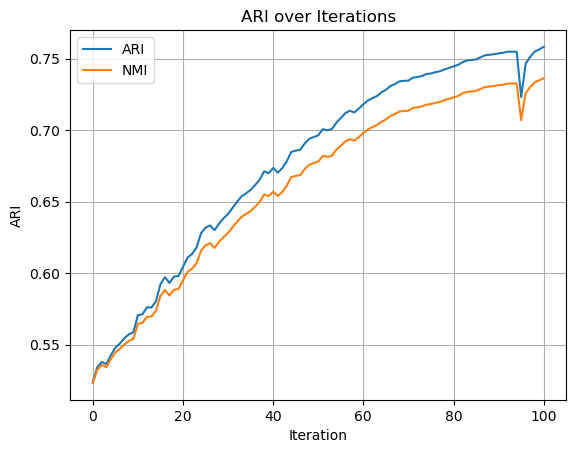

In [3]:

k = 10
final_aris = []
final_nmis = []
sc_final_aris = []
sc_final_nmis = []

# for q in np.linspace(0.12, 0.16, 16):
q = 0.155
print(f"This is the {q}th trial...")
random_state = int((time.time_ns() / 100000) % 100)
G, H = SBM(block_size=int(n/k), k=k, p=0.2, q=q)

y = [G.nodes[i]['block'] for i in G.nodes()]
print("random state = ",random_state)
# W_G = build_knn_graph(np.reshape(X, (len(X), -1)), k=3, use_gaussian=False, sigma=2)
W_G = nx.to_scipy_sparse_array(G)
# G = nx.from_scipy_sparse_matrix(W_G)

deg_g = np.array(W_G.sum(axis=1)).ravel()
normalized_Lap_G = normalized_laplacian_from_D_sp(W_G, (deg_g))
sc_labels, _, _ = spectral_clustering(
    normalized_Lap_G, 
    n_clusters=k,
    random_state=random_state
)
sc_ari = adjusted_rand_score(y, sc_labels)
sc_nmi = normalized_mutual_info_score(y, sc_labels)
sc_cut = max(conductance_all_clusters(G, sc_labels).values())
print("ARI between clustering and true labels:", sc_ari)
print("NMI between clustering and true labels:", sc_nmi)
print("Spectral clustering cut: ", sc_cut)

aris = []
nmis = []
aris.append(sc_ari)
nmis.append(sc_nmi)
cut_gh = []
cut_g = []
cut_g.append(sc_cut)
cut_gh.append(None)
pred_labels = sc_labels
n_neighbors = 2
neighbor_max = 1000
for i in range(100):

    W_H = build_cannot_link_graph(pred_labels, n_cl=min(n_neighbors + i, neighbor_max), random_state=random_state)
    H = nx.from_scipy_sparse_matrix(W_H)
    pred_labels, vals, vecs = iterative_clustering(W_G, W_H, k = k, exact=False, eps = 0.92,random_seed=random_state)
    # print("vals   ", vals)
    generalized_spectral_clustering_ari = adjusted_rand_score(y, pred_labels)
    generalized_spectral_clustering_nmi = normalized_mutual_info_score(y, pred_labels)
    print(f"{i+1}th iteration: Generalized Spectral Clustering ARI: {generalized_spectral_clustering_ari:.4f}")
    print(f"{i+1}th iteration: Generalized Spectral Clustering NMI: {generalized_spectral_clustering_nmi:.4f}")
    aris.append(generalized_spectral_clustering_ari)
    nmis.append(generalized_spectral_clustering_nmi)
    
plt.plot(aris, label = "ARI")
plt.plot(nmis, label = "NMI")
plt.xlabel('Iteration')
plt.ylabel('ARI')
plt.title('ARI over Iterations')
plt.legend()
plt.grid()
plt.show()



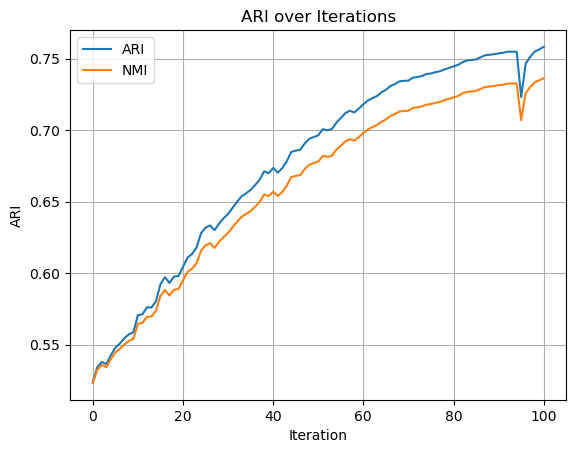

In [4]:
plt.plot(aris, label = "ARI")
plt.plot(nmis, label = "NMI")
# plt.plot(cut_g, label = "conductance")
# plt.plot(cut_gh, label = "cutratio")
plt.xlabel('Iteration')
plt.ylabel('ARI')
plt.title('ARI over Iterations')
plt.legend()
plt.grid()
plt.show()